In [ ]:
import pandas as pd

opf = pd.read_csv("order_products.csv")
af = pd.read_csv("aisles.csv")
of = pd.read_csv("orders.csv")
pf = pd.read_csv("products.csv")
depf = pd.read_csv("departments.csv")

products = pf.merge(af, on="aisle_id").merge(depf, on="department_id") # merge les produits des fichiers aisles et departments
orders = opf.merge(of, on="order_id") # merge des fichiers order_product et orders



df = orders.merge(products, on="product_id") # merge du tout pour finaliser le dataset complet

df

In [ ]:
df[df.duplicated(keep=False)]
#No duplicates to delete

In [ ]:
df.isna().sum().sort_values(ascending=False) # pour voir combien de valeurs manquantes par colonnes

In [ ]:
df["days_since_prior_order"] = df["days_since_prior_order"].fillna(df["days_since_prior_order"].mean())

disc_col = ["order_dow", "order_hour_of_day", "add_to_cart_order", "order_number"]

for col in disc_col:
    df[col] = df[col].fillna(df[col].median())

df["reordered"] = df["reordered"].fillna(0)

df = df.dropna(subset=["user_id"])

df.isna().sum().sort_values(ascending=False) # vérification

df


In [ ]:
df.to_csv('cleaned_data.csv', index=False) # créer un dataset clean

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings("ignore")

clean = pd.read_csv("cleaned_data.csv") 

#  CONFIGURATION GRAPHIQUE GLOBALE

PALETTE = ["#2D6A4F", "#40916C", "#52B788", "#74C69D",
           "#95D5B2", "#B7E4C7", "#D8F3DC"]
ACCENT  = "#1B4332"
BG      = "#F8FAF9"

plt.rcParams.update({
    "figure.facecolor":  BG,
    "axes.facecolor":    BG,
    "axes.edgecolor":    "#E63A3A",
    "axes.grid":         True,
    "grid.color":        "#4016DA",
    "grid.linestyle":    "--",
    "grid.alpha":        0.7,
    "font.family":       "DejaVu Sans",
    "font.size":         11,
    "axes.titlesize":    14,
    "axes.titleweight":  "bold",
    "axes.titlepad":     14,
    "axes.labelsize":    11,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
})

## Best seller

In [ ]:
top_products    = df["product_name"].value_counts().head(15)
top_departments = df["department"].value_counts().head(8)

fig = plt.figure(figsize=(18, 10), facecolor=BG)
fig.suptitle(
    "Quels sont les produits les plus vendus ?",
    fontsize=17, fontweight="bold", color=ACCENT, y=1.01
)

gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.35)

# Top 15 produits
ax1 = fig.add_subplot(gs[0])
colors_bar = [PALETTE[0] if i == 0 else PALETTE[2] if i < 3 else PALETTE[4]
              for i in range(len(top_products))]
bars = ax1.barh(top_products.index[::-1], top_products.values[::-1],
                color=colors_bar[::-1], edgecolor="white", linewidth=0.5)
ax1.set_title("Top 15 produits les plus commandés")
ax1.set_xlabel("Nombre de commandes")
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 500, bar.get_y() + bar.get_height() / 2,
             f"{w:,}", va="center", fontsize=9, color=ACCENT)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

# Ventes par département
ax2 = fig.add_subplot(gs[1])
wedges, texts, autotexts = ax2.pie(
    top_departments.values,
    labels=top_departments.index,
    autopct="%1.1f%%",
    colors=PALETTE[:len(top_departments)],
    startangle=140,
    wedgeprops=dict(edgecolor="white", linewidth=1.5),
    pctdistance=0.82
)
for t in autotexts:
    t.set_fontsize(9)
ax2.set_title("Répartition des ventes par département")

plt.tight_layout()
plt.savefig("section1_meilleures_ventes.png", dpi=150, bbox_inches="tight")
plt.show()


## Introduction

Cette analyse identifie les produits et rayons qui génèrent le plus de ventes.
Connaître ses best-sellers permet de prioriser les stocks, négocier avec les fournisseurs et mettre en avant les produits à fort potentiel.

## When and how do customers usually order?

In [ ]:
# Mapping jours
day_map = {0:"Lundi", 1:"Mardi", 2:"Mercredi", 3:"Jeudi",
           4:"Vendredi", 5:"Samedi", 6:"Dimanche"}
orders["day_label"] = orders["order_dow"].map(day_map)

orders_by_hour = orders["order_hour_of_day"].value_counts().sort_index()
orders_by_day  = orders["day_label"].value_counts().reindex(day_map.values())
days_since     = orders["days_since_prior_order"].dropna()

fig2, axes = plt.subplots(1, 3, figsize=(20, 6), facecolor=BG)
fig2.suptitle(
    "Quand et comment les clients commandent-ils ?",
    fontsize=17, fontweight="bold", color=ACCENT
)

explanation2 = (
    "Comprendre les habitudes temporelles des clients aide à planifier,\n"
    "La fréquence de commande révèle le degré de fidélité des acheteurs."
)
fig2.text(0.5, 1.01, explanation2, ha="center", fontsize=10,
          color="#555555", style="italic",
          bbox=dict(boxstyle="round,pad=0.4", fc="#EAF4EE", ec="#B7E4C7", alpha=0.9))

# Commandes par heure
ax = axes[0]
ax.bar(orders_by_hour.index, orders_by_hour.values,
       color=[PALETTE[0] if (10 <= h <= 16) else PALETTE[3]
              for h in orders_by_hour.index],
       edgecolor="white")
ax.set_title("Commandes par heure")
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Nombre de commandes")
ax.set_xticks(range(0, 24, 2))

peak_h = orders_by_hour.idxmax()
ax.annotate(f"Pic : {peak_h}h",
            xy=(peak_h, orders_by_hour[peak_h]),
            xytext=(peak_h + 2, orders_by_hour[peak_h] * 0.95),
            arrowprops=dict(arrowstyle="->", color=ACCENT),
            fontsize=9, color=ACCENT)

# Commandes par jour
ax = axes[1]
colors_day = [PALETTE[0] if v == orders_by_day.max() else PALETTE[3]
              for v in orders_by_day.values]
ax.bar(orders_by_day.index, orders_by_day.values,
       color=colors_day, edgecolor="white")
ax.set_title("Commandes par jour de la semaine")
ax.set_xlabel("Jour")
ax.set_ylabel("Nombre de commandes")
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

# Distribution fréquence de réachat
ax = axes[2]
ax.hist(days_since, bins=30, color=PALETTE[2], edgecolor="white", alpha=0.9)
ax.set_title("Fréquence de réachat (jours entre commandes)")
ax.set_xlabel("Jours depuis la dernière commande")
ax.set_ylabel("Nombre d'utilisateurs")
median_val = days_since.median()
ax.axvline(median_val, color=ACCENT, linestyle="--", linewidth=1.5)
ax.text(median_val + 0.5, ax.get_ylim()[1] * 0.9,
        f"Médiane : {int(median_val)}j", color=ACCENT, fontsize=9)

plt.tight_layout()
plt.savefig("section2_comportement_temporel.png", dpi=150, bbox_inches="tight")
plt.show()

## Interpretation

Comprendre les habitudes temporelles des clients aide à planifier, La fréquence de commande révèle le degré de fidélité des acheteurs.

## Can we predict whether a product will be reordered next time by a customer?

In [ ]:
# Taux de réachat par département
reorder_dept = (
    df.groupby("department")["reordered"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
reorder_dept.columns = ["department", "taux_reachat"]

# Taux de réachat selon la position dans le panier
reorder_position = (
    df.groupby("add_to_cart_order")["reordered"]
    .mean()
    .reset_index()
    .query("add_to_cart_order <= 25")
)

# Top produits les + réachetés (min 500 achats)
top_reorder = (
    df.groupby("product_name")
    .agg(total=("reordered", "count"), taux=("reordered", "mean"))
    .query("total >= 500")
    .sort_values("taux", ascending=False)
    .head(10)
    .reset_index()
)

fig3, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor=BG)
fig3.suptitle(
    "③ Peut-on prédire si un produit sera recommandé ?",
    fontsize=17, fontweight="bold", color=ACCENT
)

explanation3 = (
    "Le taux de réachat est un indicateur clé de fidélité produit.\n"
    "Les produits avec un fort taux méritent d'être toujours en stock et bien mis en avant.\n"
    "La position dans le panier révèle si le produit est un achat impulsif ou habituel."
)
fig3.text(0.5, 1.02, explanation3, ha="center", fontsize=10,
          color="#555555", style="italic",
          bbox=dict(boxstyle="round,pad=0.4", fc="#EAF4EE", ec="#B7E4C7", alpha=0.9))

# Taux par département
ax = axes[0]
bars = ax.barh(reorder_dept["department"][::-1],
               reorder_dept["taux_reachat"][::-1],
               color=[PALETTE[0] if t >= 0.6 else PALETTE[3]
                      for t in reorder_dept["taux_reachat"][::-1]],
               edgecolor="white")
ax.set_title("Taux de réachat par département")
ax.set_xlabel("Taux moyen de réachat")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.axvline(reorder_dept["taux_reachat"].mean(), color=ACCENT,
           linestyle="--", linewidth=1.2, label="Moyenne")
ax.legend(fontsize=9)

# Position dans le panier
ax = axes[1]
ax.plot(reorder_position["add_to_cart_order"],
        reorder_position["reordered"],
        color=PALETTE[0], linewidth=2.5, marker="o", markersize=4)
ax.fill_between(reorder_position["add_to_cart_order"],
                reorder_position["reordered"],
                alpha=0.15, color=PALETTE[2])
ax.set_title("Réachat selon la position dans le panier")
ax.set_xlabel("Position d'ajout au panier")
ax.set_ylabel("Taux de réachat")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

# Top produits réachetés
ax = axes[2]
ax.barh(top_reorder["product_name"][::-1],
        top_reorder["taux"][::-1],
        color=PALETTE[1], edgecolor="white")
ax.set_title("Top 10 produits les + fidélisants\n(min. 500 achats)")
ax.set_xlabel("Taux de réachat")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

plt.tight_layout()
plt.savefig("section3_prediction_reachat.png", dpi=150, bbox_inches="tight")
plt.show()

## Interpretation

Le taux de réachat est un indicateur clé de fidélité produit. Les produits avec un fort taux méritent d'être toujours en stock et bien mis en avant. La position dans le panier révèle si le produit est un achat impulsif ou habituel.

## What are the main customer profiles, such as midnight shopper, casual buyer, or cart addict?

In [ ]:
# Construction du profil par utilisateur
user_profile = (
    orders.groupby("user_id")
    .agg(
        nb_commandes        = ("order_id",               "count"),
        heure_moy           = ("order_hour_of_day",      "mean"),
        freq_reachat_moy    = ("days_since_prior_order", "mean"),
    )
    .reset_index()
)

panier_moy = (
    df.groupby("order_id")["add_to_cart_order"]
    .max()
    .reset_index()
    .rename(columns={"add_to_cart_order": "taille_panier"})
    .merge(orders[["order_id", "user_id"]], on="order_id")
    .groupby("user_id")["taille_panier"]
    .mean()
    .reset_index()
    .rename(columns={"taille_panier": "panier_moy"})
)

user_profile = user_profile.merge(panier_moy, on="user_id")

# Règles de segmentation
def segmenter(row):
    if row["heure_moy"] < 6 or row["heure_moy"] >= 22:
        return "Acheteur nocturne"
    elif row["panier_moy"] >= 15:
        return "Cart addict"
    elif row["nb_commandes"] >= 15 and row["freq_reachat_moy"] <= 10:
        return "Acheteur fidèle"
    elif row["nb_commandes"] <= 3:
        return "Acheteur occasionnel"
    else:
        return "Acheteur casual"

user_profile["segment"] = user_profile.apply(segmenter, axis=1)

segment_counts = user_profile["segment"].value_counts()


# Heure d'achat moyenne par segment
heure_segment = (
    user_profile.groupby("segment")["heure_moy"]
    .mean()
    .sort_values()
)

fig4, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor=BG)
fig4.suptitle(
    "④ Quels sont les profils clients principaux ?",
    fontsize=17, fontweight="bold", color=ACCENT
)

# Répartition des segments
ax = axes[0]
wedges, texts, autotexts = ax.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    colors=PALETTE[:len(segment_counts)],
    startangle=120,
    wedgeprops=dict(edgecolor="white", linewidth=2),
    pctdistance=0.80
)
for t in texts:
    t.set_fontsize(9)
ax.set_title("Répartition des profils clients")

# Heure d'achat par segment
ax = axes[1]
ax.barh(heure_segment.index, heure_segment.values,
        color=PALETTE[2], edgecolor="white")
ax.set_title("Heure d'achat moyenne par profil")
ax.set_xlabel("Heure moyenne (0–23)")
ax.set_xlim(0, 23)
ax.axvline(12, color=ACCENT, linestyle="--", alpha=0.5, linewidth=1, label="Midi")
ax.legend(fontsize=9)

# Distribution de la taille de panier par segment
ax = axes[2]
segments_order = user_profile["segment"].unique()
data_box = [user_profile[user_profile["segment"] == s]["panier_moy"].dropna().values
            for s in segments_order]
bp = ax.boxplot(data_box, patch_artist=True, notch=False,
                medianprops=dict(color=ACCENT, linewidth=2))
for patch, color in zip(bp["boxes"], PALETTE):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_xticklabels(segments_order, rotation=25, ha="right", fontsize=8)
ax.set_title("Taille moyenne du panier par profil")
ax.set_ylabel("Nombre de produits par commande")

plt.tight_layout()
plt.savefig("section4_profils_clients.png", dpi=150, bbox_inches="tight")
plt.show()

## Interpretation

Identifier des segments clients permet de personnaliser les offres, adapter les horaires de promotions et fidéliser les acheteurs les plus rentables.
Chaque profil a des besoins et des comportements distincts à exploiter stratégiquement.

### How can we optimize store product placement to increase profits?

### Which item do customers put in their cart first?

### Is there a correlation bettwen cart size and reordered products ?

### Which product should be emphasized during the week-end ?

## 1er model

In [ ]:
from sklearn.model_selection import train_test_split

X = clean[["order_hour_of_day", "order_dow", "days_since_prior_order", "add_to_cart_order", "aisle_id", "department_id", "order_number"]] #Targets

y = clean["reordered"] #Targets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train) #Train the model

In [ ]:
y_predict = model.predict(X_test)

In [64]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_predict)

print("Accuracy : ", accuracy)
print(classification_report(y_test, y_predict))

Accuracy :  0.70087452016056
              precision    recall  f1-score   support

         0.0       0.66      0.56      0.60   1124590
         1.0       0.72      0.80      0.76   1613826

    accuracy                           0.70   2738416
   macro avg       0.69      0.68      0.68   2738416
weighted avg       0.70      0.70      0.70   2738416



In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_predict)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=["Not Reordered", "Reordered"], yticklabels=["Not Reordered", "Reordered"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## Interpretation

627119 produits sont correctement prédits comme n'étant pas racheté. (bonne prédiction)

497471 produits sont incorrectement prédits comme racheté.(prédiction mauvaise)

321659 produits sont incorrectement prédits comme n'étant pas racheté. (prédiction mauvaise)

1292167 produits sont correctement prédits comme racheté. (bonne prédiction)


## 2ème model

In [ ]:
from sklearn.model_selection import train_test_split

X = clean[["order_hour_of_day", "order_dow", "days_since_prior_order", "add_to_cart_order", "aisle_id", "department_id", "order_number"]] #Targets

y = clean["reordered"] #Targets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train

In [57]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=100, max_depth=3, learning_rate=0.1, early_stopping=True)

hgb.fit(X_train, y_train)

Binning 0.552 GB of training data: 1.430 s
Binning 0.061 GB of validation data: 0.065 s
Fitting gradient boosted rounds:
Fit 100 trees in 54.475 s, (795 total leaves)
Time spent computing histograms: 8.870s
Time spent finding best splits:  0.046s
Time spent applying splits:      6.451s
Time spent predicting:           2.834s


,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dtype

In [58]:
y_pred = hgb.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accurate = accuracy_score(y_test, y_predict)

print("Accuracy : ", accurate)
print(classification_report(y_test, y_predict))

Binning 0.368 GB of training data: 0.734 s
Binning 0.041 GB of validation data: 0.050 s
Fitting gradient boosted rounds:
Fit 100 trees in 33.019 s, (788 total leaves)
Time spent computing histograms: 5.309s
Time spent finding best splits:  0.040s
Time spent applying splits:      3.684s
Time spent predicting:           1.318s
Binning 0.368 GB of training data: 0.706 s
Binning 0.041 GB of validation data: 0.046 s
Fitting gradient boosted rounds:
Fit 100 trees in 37.351 s, (789 total leaves)
Time spent computing histograms: 6.091s
Time spent finding best splits:  0.045s
Time spent applying splits:      4.269s
Time spent predicting:           1.448s
Binning 0.368 GB of training data: 0.734 s
Binning 0.041 GB of validation data: 0.039 s
Fitting gradient boosted rounds:
Fit 100 trees in 38.643 s, (793 total leaves)
Time spent computing histograms: 6.369s
Time spent finding best splits:  0.049s
Time spent applying splits:      4.390s
Time spent predicting:           1.389s


array([0.72951768, 0.73002812, 0.73006537])

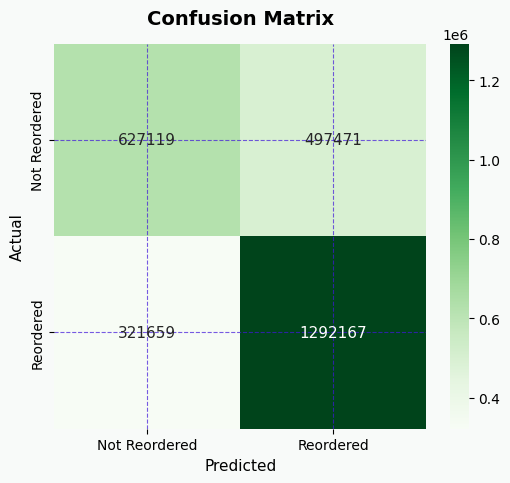

In [68]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_predict)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=["Not Reordered", "Reordered"], yticklabels=["Not Reordered", "Reordered"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## Comparaison des models

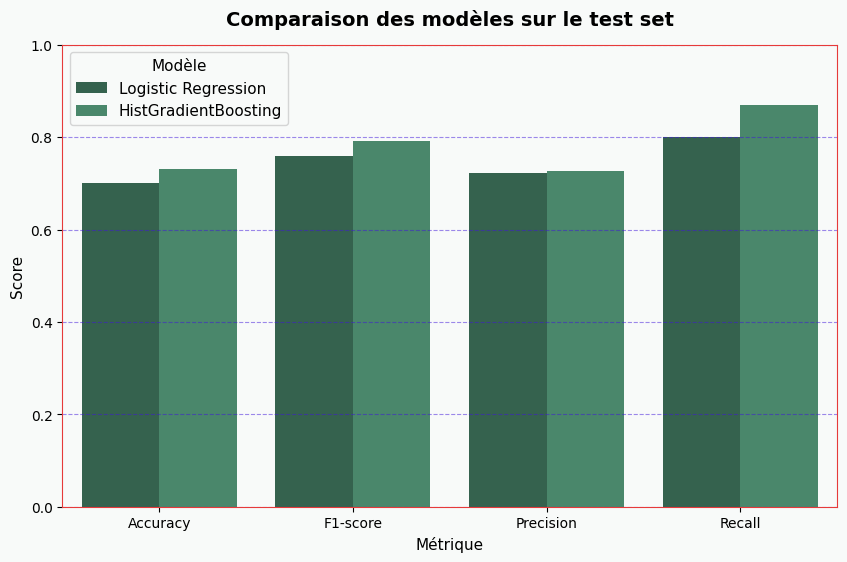

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

y_pred_log = model.predict(X_test)
y_pred_hgb = hgb.predict(X_test) 

metrics = {
    "Model": ["Logistic Regression"]*4 + ["HistGradientBoosting"]*4,
    "Metric": ["Accuracy", "F1-score", "Precision", "Recall"]*2,
    "Score": [
        accuracy_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_hgb),
        f1_score(y_test, y_pred_hgb),
        precision_score(y_test, y_pred_hgb),
        recall_score(y_test, y_pred_hgb)
    ]
}

metrics_df = pd.DataFrame(metrics)

plt.figure(figsize=(10,6))
sns.barplot(x="Metric", y="Score", hue="Model", data=metrics_df, palette=["#2D6A4F", "#40916C"])

plt.ylim(0, 1)
plt.title("Comparaison des modèles sur le test set", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("Métrique")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(title="Modèle")
plt.show()